# 1.1 — Reglas de limpieza: viajes de MiBici

* **Equipo:** 9
* **Curso:** TC5044.10 MLOps
* **Rol:** Data Engineer

**Objetivo.** Definir, con evidencia, qué viajes se eliminan o corrigen antes de construir la demanda por
zona y hora. Cada regla sale de una prueba de diagnóstico; las reglas se escriben como funciones puras y
se aplican a todos los meses descargados, con una bitácora de cuántas filas toca cada paso.

**Regla de trabajo.** Ningún viaje se elimina sin una prueba que lo justifique. Los límites salen del
dominio (cómo funciona un sistema de bicis compartidas) y son deliberadamente amplios: buscan viajes
**imposibles**, no viajes raros.

**Requisito.** Datos descargados con `make data` (o `python -m proyecto_mlops_equipo_9.download`).

> Las funciones de la sección 4 se pasan después a `cleaning.py`.

## Los datos

Cada fila de los CSV mensuales es **un viaje**: se toma una bici en una estación y se ancla en otra (o en la
misma). El cargador `cargar_mes` de `dataset.py` estandariza los nombres de columna:

| Columna | Qué es |
|---|---|
| `viaje_id` | Identificador del viaje |
| `usuario_id` | Identificador del usuario |
| `genero`, `anio_nacimiento` | Datos declarados por el usuario |
| `inicio`, `fin` | Fecha y hora de desanclaje y anclaje |
| `origen_id`, `destino_id` | Estaciones; corresponden al `id` del catálogo |
| `duracion_min` | Agregada por el cargador: `fin − inicio` en minutos |

El catálogo de estaciones (`nomenclatura_2026_09.csv`) trae `id`, nombre, latitud, longitud y `dpcapacity`.

### 1. Configuración

In [1]:
# ------ Import Libraries ----------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from proyecto_mlops_equipo_9.config import FIGURES_DIR
from proyecto_mlops_equipo_9.dataset import (
    COLUMNAS, cargar_estaciones, cargar_mes, columnas_mes, meses_disponibles,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

2026-10-22 21:15:51.960 | INFO     | proyecto_mlops_equipo_9.config:<module>:11 - PROJ_ROOT path is: /home/ludwigvi/proyectos_mna/mlops/Proyecto_MLOPS_Equipo_9


In [2]:
# ------ Figures ----------

FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save_figure(fig, name):
    """Guarda la figura en reports/figures para usarla en el reporte."""
    fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

### 2. Carga de los datos

Las pruebas se exploran en detalle sobre **junio de 2026**: es el mes con más problemas (transición a las
bicis eléctricas, el 5 de junio atípico y estaciones fuera del catálogo). En la sección 4 el pipeline se
aplica a **todos** los meses descargados.

In [3]:
MESES = meses_disponibles()
MES_DETALLE = "2026_06"

print(f"Meses descargados: {len(MESES)} ({MESES[0]} a {MESES[-1]})")

raw_df = cargar_mes(MES_DETALLE)
estaciones = cargar_estaciones()
coords = estaciones.set_index("id")[["latitude", "longitude"]]

print(f"{MES_DETALLE}: {len(raw_df):,} viajes   Catálogo: {len(estaciones)} estaciones")
raw_df.head()

Meses descargados: 21 (2025_01 a 2026_09)
2026_06: 355,303 viajes   Catálogo: 484 estaciones


,viaje_id,usuario_id,genero,anio_nacimiento,inicio,fin,origen_id,destino_id,duracion_min
0,44407944,252161,M,1983.0,2026-06-01 00:06:46,2026-06-01 00:09:53,16,30,3.116667
1,44407945,4707664,F,1990.0,2026-06-01 00:07:19,2026-06-01 00:26:47,32,175,19.466667
2,44407949,4572563,M,2003.0,2026-06-01 00:10:51,2026-06-01 00:31:56,263,270,21.083333
3,44407957,4036274,M,1988.0,2026-06-01 00:15:44,2026-06-01 00:21:47,38,81,6.050000
4,44407964,4711556,M,1988.0,2026-06-01 00:21:55,2026-06-01 00:35:08,26,159,13.216667


In [4]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 355303 entries, 0 to 355302
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   viaje_id         355303 non-null  int64         
 1   usuario_id       355303 non-null  int64         
 2   genero           353020 non-null  category      
 3   anio_nacimiento  355293 non-null  float64       
 4   inicio           355303 non-null  datetime64[ns]
 5   fin              355303 non-null  datetime64[ns]
 6   origen_id        355303 non-null  int64         
 7   destino_id       355303 non-null  int64         
 8   duracion_min     355303 non-null  float64       
dtypes: category(1), datetime64[ns](2), float64(2), int64(4)
memory usage: 22.0 MB


### 3. Pruebas de diagnóstico

Antes de eliminar cualquier viaje, se **mide**. Cada prueba responde una pregunta y define una acción:

| # | Prueba | Si falla → acción |
|---|---|---|
| T1 | Esquema: ¿todos los meses traen las columnas del contrato? | Detenerse si falta alguna |
| T2 | Tipos y periodo: ¿fechas válidas y dentro del mes del archivo? | Eliminar filas sin fecha válida |
| T3 | Duplicados: ¿hay viajes repetidos? | Eliminar copias |
| T4 | Duración no positiva: ¿`fin` ≤ `inicio`? | Eliminar |
| T5 | Desanclajes fallidos: ¿viajes de segundos en la misma estación? | Eliminar |
| T6 | Velocidad imposible: ¿viajes entre estaciones distintas más rápidos de lo posible? | Eliminar |
| T7 | Duración excesiva: ¿viajes de muchas horas? | Eliminar |
| T8 | Estaciones fuera del catálogo: ¿ids sin ubicación? | Eliminar (no se pueden asignar a una zona) |
| T9 | Datos del usuario: ¿género y edad válidos? | Conservar el viaje; edad imposible → faltante |

#### 3.0 Contrato de datos

El contrato describe cómo se ve un viaje válido. Los límites salen del dominio, no de un ajuste estadístico.

In [5]:
EXPECTED_COLUMNS = COLUMNAS                 # contrato de columnas (dataset.py)
GENEROS_VALIDOS = {"M", "F"}                # valores que publica MiBici; el faltante se permite

# Un desanclaje y reanclaje en la misma estación en menos de 1 minuto no es un viaje:
# es un intento fallido o un cambio de bici
DURACION_MIN_MISMA_ESTACION_S = 60

# Velocidad en línea recta entre estaciones. Los viajes reales rara vez superan 20 km/h y las bicis
# de sistemas públicos casi nunca pasan de 25 km/h; 30 km/h deja margen. La línea recta subestima la
# ruta real, así que la regla es conservadora: solo marca viajes que serían imposibles
VELOCIDAD_MAX_KMH = 30

# Un préstamo de más de 3 horas en un sistema de viajes cortos indica una bici mal anclada
# o un error de registro (decisión del analista; afecta muy pocos viajes)
DURACION_MAX_MIN = 180

# MiBici solo registra usuarios de 16 años o más; más de 90 años se considera captura errónea
EDAD_MIN, EDAD_MAX = 16, 90

#### 3.1 T1 - Esquema

* **Qué revisa:** las columnas de cada mes descargado contra el contrato.
* **Por qué importa:** si un mes cambia de formato, todas las etapas siguientes fallan o, peor, mezclan columnas.

In [7]:
esquema = pd.DataFrame([
    {"mes": mes, "coincide": columnas_mes(mes) == EXPECTED_COLUMNS,
     "extra": sorted(set(columnas_mes(mes)) - set(EXPECTED_COLUMNS)),
     "faltan": sorted(set(EXPECTED_COLUMNS) - set(columnas_mes(mes)))}
    for mes in MESES
]).set_index("mes")

print(f"Meses con las columnas del contrato: {esquema['coincide'].sum()} de {len(esquema)}")
display(esquema[~esquema["coincide"]])

Meses con las columnas del contrato: 21 de 21


,coincide,extra,faltan
mes,,,


**Resultado → acción.** Si todos los meses coinciden, no hay acción. El cargador conserva cualquier
columna desconocida con su nombre, así que un cambio de formato aparecería aquí.

#### 3.2 T2 - Tipos y periodo

* **Qué revisa:** que `inicio` y `fin` sean fechas válidas, que `inicio` caiga dentro del mes del archivo
y en qué horas empiezan los viajes.
* **Por qué importa:** un viaje fuera de su mes se contaría dos veces al juntar meses; una fecha inválida
no se puede asignar a una hora.

In [9]:
anio, mes = map(int, MES_DETALLE.split("_"))
tipos = pd.Series({
    "inicio inválido": int(raw_df["inicio"].isna().sum()),
    "fin inválido": int(raw_df["fin"].isna().sum()),
    "inicio fuera del mes": int(((raw_df["inicio"].dt.year != anio) | (raw_df["inicio"].dt.month != mes)).sum()),
    "inicio entre 1:00 y 4:59": int(raw_df["inicio"].dt.hour.between(1, 4).sum()),
}, name="viajes")
display(tipos.to_frame())

,viajes
inicio inválido,0
fin inválido,0
inicio fuera del mes,0
inicio entre 1:00 y 4:59,35


**Resultado → acción.** En junio de 2026 todas las fechas son válidas y caen dentro del mes. Hay unas
decenas de viajes que empiezan entre 1:00 y 4:59, fuera del horario habitual (aprox. 5:00 a 0:59); pueden
ser devoluciones tardías reales → **sin acción**, solo diagnóstico. El pipeline elimina por seguridad
cualquier fila sin fecha válida (paso 1).

#### 3.3 T3 - Duplicados

* **Qué revisa:** filas idénticas y `viaje_id` repetidos.
* **Por qué importa:** un viaje duplicado infla la demanda de esa zona y hora.

In [10]:
duplicados = pd.Series({
    "filas idénticas": int(raw_df.duplicated().sum()),
    "viaje_id repetido": int(raw_df["viaje_id"].duplicated().sum()),
}, name="viajes")
display(duplicados.to_frame())

,viajes
filas idénticas,0
viaje_id repetido,0


**Resultado → acción.** Junio de 2026 no tiene duplicados; septiembre de 2026 sí (se verá en la bitácora
de la sección 4). Cuando aparecen, son filas idénticas → **conservar una copia**.

#### 3.4 T4 - Duración no positiva

* **Qué revisa:** viajes donde `fin` es igual o anterior a `inicio`.
* **Por qué importa:** un viaje de 0 segundos no existe; con duración negativa, además, la velocidad (T6)
no se puede calcular.

In [11]:
no_positiva = raw_df["duracion_min"] <= 0
print(f"Duración ≤ 0: {no_positiva.sum():,} viajes "
      f"(negativa: {(raw_df['duracion_min'] < 0).sum():,}, cero: {(raw_df['duracion_min'] == 0).sum():,})")

Duración ≤ 0: 116 viajes (negativa: 0, cero: 116)


**Resultado → acción.** Todos los casos son de duración exactamente 0 → **eliminarlos**.

#### 3.5 T5 - Desanclajes fallidos

* **Qué revisa:** viajes que salen y regresan a la misma estación en pocos segundos.
* **Por qué importa:** son intentos fallidos o cambios de bici, no demanda. Un viaje largo que regresa a la
misma estación sí es real, así que la regla solo aplica a duraciones cortas.

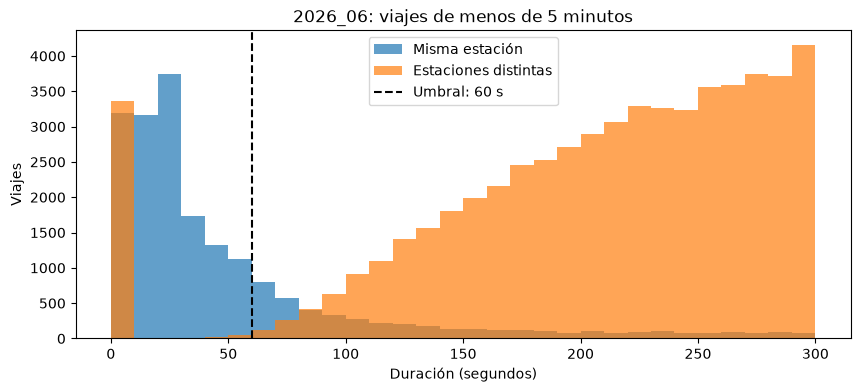

Misma estación y menos de  10s: 3,189
Misma estación y menos de  30s: 10,095
Misma estación y menos de  60s: 14,288
Misma estación y menos de 120s: 16,900


In [13]:
misma = raw_df["origen_id"] == raw_df["destino_id"]
segundos = raw_df["duracion_min"] * 60

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0, 301, 10)
ax.hist(segundos[misma & segundos.between(0, 300)], bins=bins, alpha=0.7, label="Misma estación")
ax.hist(segundos[~misma & segundos.between(0, 300)], bins=bins, alpha=0.7, label="Estaciones distintas")
ax.axvline(DURACION_MIN_MISMA_ESTACION_S, color="black", linestyle="--", label="Umbral: 60 s")
ax.set_xlabel("Duración (segundos)")
ax.set_ylabel("Viajes")
ax.set_title(f"{MES_DETALLE}: viajes de menos de 5 minutos")
ax.legend()
save_figure(fig, "1_1_desanclajes_fallidos")
plt.show()

for umbral in [10, 30, 60, 120]:
    print(f"Misma estación y menos de {umbral:>3}s: {(misma & (segundos < umbral)).sum():,}")

**Resultado → acción.** Los viajes de la misma estación se acumulan en los primeros segundos y la curva
cae hasta los ~90 s; después se vuelve casi plana (unos 100 viajes cada 10 s), que corresponde a paseos
cortos reales. En junio de 2026 hay 14,288 viajes de la misma estación de menos de 60 s. Subir el umbral
a 90 s eliminaría 1,786 viajes más; se elige 60 s porque en menos de un minuto no hay un viaje de ida y
vuelta, y así no se arriesga eliminar demanda real → **eliminar viajes de la misma estación de menos de
60 s**. (Los viajes de 0–10 s entre estaciones *distintas* se tratan en T6.)

#### 3.6 T6 - Velocidad imposible

* **Qué revisa:** la velocidad implícita de cada viaje entre estaciones distintas: distancia en línea recta
(fórmula del haversine) entre la duración.
* **Por qué importa:** un viaje de 2 segundos entre estaciones a 1 km es un error de registro, no un viaje.
La regla usa la ubicación real de las estaciones en lugar de un umbral fijo de segundos.

In [14]:
def velocidad_kmh(df, coords):
    """Velocidad en línea recta (km/h). NaN si alguna estación no está en el catálogo."""
    origen = coords.reindex(df["origen_id"]).to_numpy()
    destino = coords.reindex(df["destino_id"]).to_numpy()
    lat1, lon1, lat2, lon2 = (np.radians(a) for a in (origen[:, 0], origen[:, 1], destino[:, 0], destino[:, 1]))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    distancia_km = 2 * 6371 * np.arcsin(np.sqrt(a))
    with np.errstate(divide="ignore", invalid="ignore"):
        velocidad = distancia_km / (df["duracion_min"].to_numpy() / 60)
    return pd.Series(velocidad, index=df.index)


evaluables = ~misma & (raw_df["duracion_min"] > 0)
velocidad = velocidad_kmh(raw_df[evaluables], coords).dropna()

print("Percentiles de velocidad (km/h):", velocidad.quantile([0.5, 0.9, 0.99]).round(1).to_dict())
for limite in [25, 30, 40, 60]:
    print(f"Más de {limite} km/h: {(velocidad > limite).sum():,}")

Percentiles de velocidad (km/h): {0.5: 8.9, 0.9: 13.2, 0.99: 222.0}
Más de 25 km/h: 3,258
Más de 30 km/h: 3,253
Más de 40 km/h: 3,250
Más de 60 km/h: 3,250


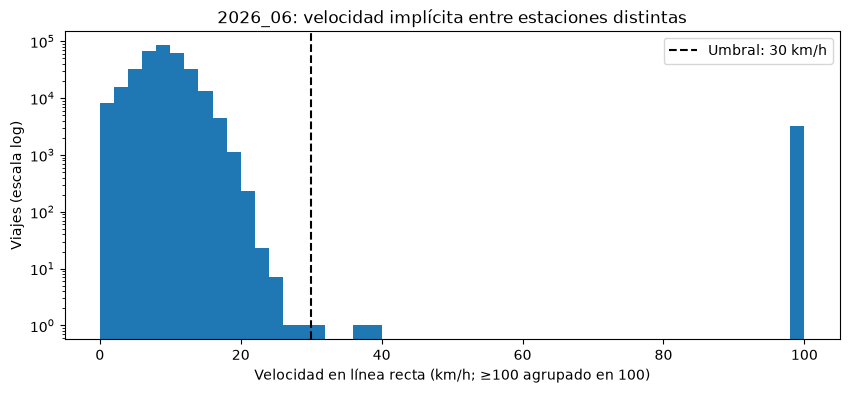

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(velocidad.clip(upper=100), bins=np.arange(0, 101, 2))
ax.axvline(VELOCIDAD_MAX_KMH, color="black", linestyle="--", label=f"Umbral: {VELOCIDAD_MAX_KMH} km/h")
ax.set_yscale("log")
ax.set_xlabel("Velocidad en línea recta (km/h; ≥100 agrupado en 100)")
ax.set_ylabel("Viajes (escala log)")
ax.set_title(f"{MES_DETALLE}: velocidad implícita entre estaciones distintas")
ax.legend()
save_figure(fig, "1_1_velocidad_imposible")
plt.show()

**Resultado → acción.** La mediana es de 9 km/h y el 90% de los viajes va a menos de 13 km/h; la
distribución real termina antes de 30 km/h. Entre 25 y 60 km/h casi no hay viajes (3,258 contra 3,250 por
encima de cada límite en junio de 2026), así que hay una separación clara entre viajes reales y errores, y
el umbral no es sensible. Los casos imposibles se acumulan en
velocidades de cientos o miles de km/h → **eliminar viajes de más de 30 km/h**.

#### 3.7 T7 - Duración excesiva

* **Qué revisa:** cuántos viajes duran varias horas.
* **Por qué importa:** MiBici está pensado para viajes cortos; un préstamo de un día entero suele ser una bici
mal anclada que se cierra después, y sumaría demanda en una hora que no le corresponde.

In [16]:
largos = pd.Series({f"más de {h} min": int((raw_df["duracion_min"] > h).sum()) for h in [60, 120, 180, 240, 480, 1440]},
                   name="viajes")
display(largos.to_frame())
print(f"Duración máxima: {raw_df['duracion_min'].max() / 60:.1f} horas")

,viajes
más de 60 min,525
más de 120 min,134
más de 180 min,68
más de 240 min,50
más de 480 min,22
más de 1440 min,6


Duración máxima: 37.0 horas


**Resultado → acción.** Muy pocos viajes pasan de 3 horas (68 en junio de 2026, 0.02%), pero llegan hasta
más de un día → **eliminar viajes de más de 180 min**. El umbral es una decisión del analista; por el
tamaño, cambiarlo no altera la demanda agregada.

#### 3.8 T8 - Estaciones fuera del catálogo

* **Qué revisa:** `origen_id` y `destino_id` que no existen en el catálogo, y el uso de estaciones dadas de baja (`ex-`).
* **Por qué importa:** sin ubicación, el viaje no se puede asignar a una zona ni calcular su velocidad.

In [17]:
ids_catalogo = set(estaciones["id"])
ids_viajes = set(raw_df["origen_id"]) | set(raw_df["destino_id"])
fuera = sorted(ids_viajes - ids_catalogo)
usa_fuera = raw_df["origen_id"].isin(fuera) | raw_df["destino_id"].isin(fuera)

print(f"Ids fuera del catálogo: {fuera} → {usa_fuera.sum():,} viajes")
print("Primer día con viajes en esas estaciones:", raw_df.loc[usa_fuera, "inicio"].min())

ids_baja = set(estaciones.loc[estaciones["dada_de_baja"], "id"])
print(f"Viajes que usan estaciones 'ex-': {(raw_df['origen_id'].isin(ids_baja) | raw_df['destino_id'].isin(ids_baja)).sum():,}")

Ids fuera del catálogo: [405, 407] → 1,980 viajes
Primer día con viajes en esas estaciones: 2026-06-08 18:03:12
Viajes que usan estaciones 'ex-': 0


**Resultado → acción.** En junio de 2026 aparecen dos ids que no están en el catálogo (405 y 407), con
1,980 viajes a partir del 8 de junio; no hay forma de ubicarlos → **eliminar esos viajes**. Las estaciones
dadas de baja (`ex-`) **se conservan**: no tienen viajes en 2026, pero en meses anteriores sí funcionaban,
y sus viajes son demanda real de su zona en ese momento.

#### 3.9 T9 - Datos del usuario

* **Qué revisa:** valores de `genero` y la edad (`año del viaje − anio_nacimiento`).
* **Por qué importa:** no se usan para predecir la demanda, pero sí en el EDA; una edad de 1,800 años
distorsiona cualquier estadística.

In [19]:
edad = raw_df["inicio"].dt.year - raw_df["anio_nacimiento"]
usuario = pd.Series({
    "género faltante": int(raw_df["genero"].isna().sum()),
    "género fuera de M/F": int((~raw_df["genero"].isin(GENEROS_VALIDOS) & raw_df["genero"].notna()).sum()),
    "año de nacimiento faltante": int(raw_df["anio_nacimiento"].isna().sum()),
    f"edad < {EDAD_MIN}": int((edad < EDAD_MIN).sum()),
    f"edad > {EDAD_MAX}": int((edad > EDAD_MAX).sum()),
}, name="viajes")
display(usuario.to_frame())
print(f"Edad máxima registrada: {edad.max():.0f} años")

,viajes
género faltante,2283
género fuera de M/F,0
año de nacimiento faltante,10
edad < 16,0
edad > 90,26


Edad máxima registrada: 1827 años


**Resultado → acción.** El género falta en menos de 1% de los viajes y solo toma valores M/F. Hay edades
imposibles (hasta 1,827 años) → **conservar el viaje**, porque es demanda real, y **convertir la edad
imposible a faltante**. El género faltante se deja como está.

### 4. Pipeline de limpieza

Cada prueba se traduce en una **función pura**: recibe un DataFrame y devuelve uno nuevo, sin estado oculto.
Así cada paso se puede probar por separado y el mismo pipeline corre igual con meses nuevos.

Una **bitácora** registra, por mes y por paso, cuántas filas entraron, cuántas salieron y cuántas celdas
cambiaron. Es lo que se registra en MLflow junto con la versión limpia del dataset.

| Paso | Función | Viene de |
|---|---|---|
| 1 | `eliminar_fechas_invalidas` | T2 |
| 2 | `eliminar_duplicados` | T3 |
| 3 | `eliminar_duracion_no_positiva` | T4 |
| 4 | `eliminar_desanclajes_fallidos` | T5 |
| 5 | `eliminar_estaciones_fuera_de_catalogo` | T8 (antes de T6: la velocidad necesita ubicación) |
| 6 | `eliminar_velocidad_imposible` | T6 |
| 7 | `eliminar_duracion_excesiva` | T7 |
| 8 | `corregir_edad_imposible` | T9 |

In [20]:
def eliminar_fechas_invalidas(df):
    return df[df["inicio"].notna() & df["fin"].notna()]


def eliminar_duplicados(df):
    return df.drop_duplicates(subset="viaje_id")


def eliminar_duracion_no_positiva(df):
    return df[df["duracion_min"] > 0]


def eliminar_desanclajes_fallidos(df):
    fallido = (df["origen_id"] == df["destino_id"]) & (df["duracion_min"] * 60 < DURACION_MIN_MISMA_ESTACION_S)
    return df[~fallido]


def eliminar_estaciones_fuera_de_catalogo(df, coords):
    return df[df["origen_id"].isin(coords.index) & df["destino_id"].isin(coords.index)]


def eliminar_velocidad_imposible(df, coords):
    return df[velocidad_kmh(df, coords) <= VELOCIDAD_MAX_KMH]


def eliminar_duracion_excesiva(df):
    return df[df["duracion_min"] <= DURACION_MAX_MIN]


def corregir_edad_imposible(df):
    edad = df["inicio"].dt.year - df["anio_nacimiento"]
    return df.assign(anio_nacimiento=df["anio_nacimiento"].where(edad.between(EDAD_MIN, EDAD_MAX)))

In [21]:
def limpiar_mes(df, mes, coords):
    """Aplica los pasos en orden. Regresa el mes limpio y su bitácora."""
    pasos = [
        ("1 eliminar_fechas_invalidas", eliminar_fechas_invalidas),
        ("2 eliminar_duplicados", eliminar_duplicados),
        ("3 eliminar_duracion_no_positiva", eliminar_duracion_no_positiva),
        ("4 eliminar_desanclajes_fallidos", eliminar_desanclajes_fallidos),
        ("5 eliminar_estaciones_fuera_de_catalogo", lambda d: eliminar_estaciones_fuera_de_catalogo(d, coords)),
        ("6 eliminar_velocidad_imposible", lambda d: eliminar_velocidad_imposible(d, coords)),
        ("7 eliminar_duracion_excesiva", eliminar_duracion_excesiva),
        ("8 corregir_edad_imposible", corregir_edad_imposible),
    ]
    bitacora = []
    for paso, funcion in pasos:
        antes, faltantes_antes = len(df), int(df["anio_nacimiento"].isna().sum())
        df = funcion(df)
        # Las celdas modificadas solo se cuentan en pasos que no eliminan filas (paso 8)
        celdas = int(df["anio_nacimiento"].isna().sum()) - faltantes_antes if len(df) == antes else 0
        bitacora.append({
            "mes": mes, "paso": paso, "filas_antes": antes, "filas_despues": len(df),
            "filas_eliminadas": antes - len(df), "celdas_modificadas": celdas,
        })
    return df.reset_index(drop=True), bitacora

In [22]:
clean_df, bitacora_detalle = limpiar_mes(raw_df, MES_DETALLE, coords)
print(f"{MES_DETALLE}: {len(raw_df):,} → {len(clean_df):,} viajes ({1 - len(clean_df) / len(raw_df):.1%} eliminados)")
pd.DataFrame(bitacora_detalle)

2026_06: 355,303 → 335,665 viajes (5.5% eliminados)


,mes,paso,filas_antes,filas_despues,filas_eliminadas,celdas_modificadas
0,2026_06,1 eliminar_fechas_invalidas,355303,355303,0,0
1,2026_06,2 eliminar_duplicados,355303,355303,0,0
2,2026_06,3 eliminar_duracion_no_positiva,355303,355187,116,0
3,2026_06,4 eliminar_desanclajes_fallidos,355187,340921,14266,0
4,2026_06,5 eliminar_estaciones_fuera_de_catalogo,340921,338985,1936,0
5,2026_06,6 eliminar_velocidad_imposible,338985,335732,3253,0
6,2026_06,7 eliminar_duracion_excesiva,335732,335665,67,0
7,2026_06,8 corregir_edad_imposible,335665,335665,0,25


### 5. Validación posterior a la limpieza

La limpieza no termina hasta demostrar que el resultado cumple el contrato. Estas aserciones correrían
automáticamente en el pipeline: si una falla, se detiene.

| Aserción | Prueba de origen |
|---|---|
| Columnas del contrato | T1 |
| Fechas válidas y dentro del mes | T2 |
| Sin viajes repetidos | T3 |
| Duración > 0 y ≤ 180 min | T4, T7 |
| Sin desanclajes fallidos | T5 |
| Estaciones en el catálogo y velocidad ≤ 30 km/h | T6, T8 |
| Género M/F o faltante; edad 16–90 o faltante | T9 |

In [23]:
def validar(df, mes, coords):
    """Comprueba que un mes limpio cumple el contrato; si algo falla, se detiene."""
    anio, num_mes = map(int, mes.split("_"))
    assert list(df.columns[: len(EXPECTED_COLUMNS)]) == EXPECTED_COLUMNS, "columnas del contrato"
    assert df["inicio"].notna().all() and df["fin"].notna().all(), "fechas válidas"
    assert ((df["inicio"].dt.year == anio) & (df["inicio"].dt.month == num_mes)).all(), "inicio dentro del mes"
    assert df["viaje_id"].is_unique, "sin viajes repetidos"
    assert df["duracion_min"].between(0, DURACION_MAX_MIN, inclusive="right").all(), "duración en (0, 180] min"
    misma = df["origen_id"] == df["destino_id"]
    assert not (misma & (df["duracion_min"] * 60 < DURACION_MIN_MISMA_ESTACION_S)).any(), "sin desanclajes fallidos"
    assert df["origen_id"].isin(coords.index).all() and df["destino_id"].isin(coords.index).all(), "estaciones en catálogo"
    assert (velocidad_kmh(df, coords) <= VELOCIDAD_MAX_KMH).all(), "velocidad posible"
    assert (df["genero"].isin(GENEROS_VALIDOS) | df["genero"].isna()).all(), "género M/F o faltante"
    edad = df["inicio"].dt.year - df["anio_nacimiento"]
    assert (edad.between(EDAD_MIN, EDAD_MAX) | edad.isna()).all(), "edad 16-90 o faltante"


validar(clean_df, MES_DETALLE, coords)
print(f"{MES_DETALLE}: cumple el contrato")

2026_06: cumple el contrato


#### 5.1 Todos los meses

Se aplica el pipeline mes por mes (un mes en memoria a la vez), se valida cada resultado y se guardan los
viajes válidos por día para la sección 6. Tarda alrededor de un minuto con 21 meses.

In [24]:
bitacora = []
diarios = []

for mes in MESES:
    limpio, bitacora_mes = limpiar_mes(cargar_mes(mes), mes, coords)
    validar(limpio, mes, coords)
    bitacora.extend(bitacora_mes)
    diarios.append(limpio.groupby(limpio["inicio"].dt.normalize()).size())

bitacora = pd.DataFrame(bitacora)
diarios = pd.concat(diarios).rename("viajes_validos")
print(f"{len(MESES)} meses limpios y validados")

21 meses limpios y validados


In [25]:
# Viajes eliminados por paso y por mes (en filas)
eliminados = bitacora.pivot(index="mes", columns="paso", values="filas_eliminadas")
eliminados.insert(0, "viajes_crudos", bitacora.groupby("mes")["filas_antes"].first())
eliminados["viajes_limpios"] = bitacora.groupby("mes")["filas_despues"].last()
eliminados["pct_eliminado"] = (1 - eliminados["viajes_limpios"] / eliminados["viajes_crudos"]) * 100
eliminados.round(2)

paso,viajes_crudos,1 eliminar_fechas_invalidas,2 eliminar_duplicados,3 eliminar_duracion_no_positiva,4 eliminar_desanclajes_fallidos,5 eliminar_estaciones_fuera_de_catalogo,6 eliminar_velocidad_imposible,7 eliminar_duracion_excesiva,8 corregir_edad_imposible,viajes_limpios,pct_eliminado
mes,,,,,,,,,,,
2025_01,380184,0,0,205,8749,0,270,45,0,370915,2.44
2025_02,372529,0,0,194,8490,0,273,42,0,363530,2.42
2025_03,405110,0,0,216,9706,0,371,52,0,394765,2.55
2025_04,366193,0,0,185,8670,0,230,20,0,357088,2.49
2025_05,395891,0,0,189,9493,0,313,32,0,385864,2.53
2025_06,356611,0,0,278,8929,0,487,50,0,346867,2.73
2025_07,368186,0,0,253,9184,0,290,35,0,358424,2.65
2025_08,374727,0,0,275,9456,0,324,33,0,364639,2.69
2025_09,376789,0,0,228,9543,0,401,35,0,366582,2.71


In [27]:
# Resumen de todos los meses
resumen = bitacora.groupby("paso").agg(filas_eliminadas=("filas_eliminadas", "sum"),
                                       celdas_modificadas=("celdas_modificadas", "sum"))
total_crudos = bitacora.groupby("mes")["filas_antes"].first().sum()
resumen["pct_del_total"] = resumen["filas_eliminadas"] / total_crudos * 100
print(f"Total: {total_crudos:,} viajes crudos → {bitacora.groupby('mes')['filas_despues'].last().sum():,} limpios")
resumen.round(3)

Total: 7,894,097 viajes crudos → 7,644,409 limpios


,filas_eliminadas,celdas_modificadas,pct_del_total
paso,,,
1 eliminar_fechas_invalidas,0,0,0.000
2 eliminar_duplicados,758,0,0.010
3 eliminar_duracion_no_positiva,5814,0,0.074
4 eliminar_desanclajes_fallidos,221119,0,2.801
5 eliminar_estaciones_fuera_de_catalogo,3888,0,0.049
6 eliminar_velocidad_imposible,17256,0,0.219
7 eliminar_duracion_excesiva,853,0,0.011
8 corregir_edad_imposible,0,708,0.000


### 6. Días atípicos

* **Qué revisa:** días cuya cantidad de viajes válidos queda muy por debajo de lo normal para ese día de la
semana en el mismo mes.
* **Por qué importa:** un día con el sistema caído o en mantenimiento no es demanda baja real; el modelo no
debería aprender de él. No se eliminan viajes: se marcan los días para decidir en la Fase 2.

In [28]:
UMBRAL_ATIPICO = 0.6  # menos del 60% de la mediana de su día de la semana en el mes

dias = diarios.to_frame()
dias["mes"] = dias.index.to_period("M")
dias["dia_semana"] = dias.index.dayofweek
dias["referencia"] = dias.groupby(["mes", "dia_semana"])["viajes_validos"].transform("median")
dias["proporcion"] = dias["viajes_validos"] / dias["referencia"]
atipicos = dias[dias["proporcion"] < UMBRAL_ATIPICO]

display(atipicos[["viajes_validos", "referencia", "proporcion"]].round(2))

,viajes_validos,referencia,proporcion
inicio,,,
2025-01-01,3306,14534.0,0.23
2025-02-03,8041,14525.5,0.55
2025-03-17,7820,14658.0,0.53
2025-04-18,6721,12841.0,0.52
2025-05-01,8044,13788.0,0.58
2025-09-16,6481,14541.0,0.45
2025-11-17,7718,13978.5,0.55
2025-12-24,7034,12951.0,0.54
2025-12-25,3014,13074.0,0.23


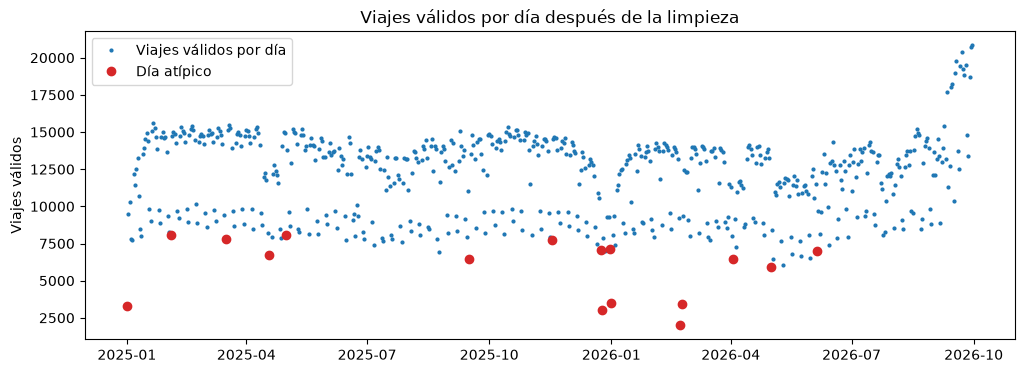

In [29]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dias.index, dias["viajes_validos"], ".", markersize=4, label="Viajes válidos por día")
ax.plot(atipicos.index, atipicos["viajes_validos"], "o", color="tab:red", label="Día atípico")
ax.set_ylabel("Viajes válidos")
ax.set_title("Viajes válidos por día después de la limpieza")
ax.legend()
save_figure(fig, "1_1_dias_atipicos")
plt.show()

**Resultado → acción.** La prueba encuentra dos tipos de días:
- **Festivos**, como el 1 de mayo (Día del Trabajo) en 2025 y en 2026: la demanda baja es real y la explica
  el calendario → **se conservan**; la variable `festivo` de `features.py` le enseña al modelo ese patrón.
- **Fallas del sistema**, como el 5 de junio de 2026, que sigue muy por debajo de un viernes normal incluso
  después de quitar los viajes inválidos → **se marcan** para decidir en la Fase 2 si se excluyen del
  entrenamiento.

Ambos se registran a mano en `references/dias_especiales.csv` (fecha, tipo y motivo).

### 7. Conclusiones

#### Reglas de limpieza

| Prueba | Problema | Acción |
|---|---|---|
| T1 | Cambios de formato entre meses | Ninguno: mismas 8 columnas en todos los meses |
| T2 | Fechas inválidas o fuera del mes | Eliminar (paso 1) |
| T3 | Viajes duplicados (septiembre 2026) | Conservar una copia (paso 2) |
| T4 | Duración de 0 segundos | Eliminar (paso 3) |
| T5 | Desanclajes fallidos: misma estación, < 60 s | Eliminar (paso 4) |
| T8 | Estaciones fuera del catálogo (405 y 407 desde junio 2026) | Eliminar (paso 5) |
| T6 | Velocidad en línea recta > 30 km/h | Eliminar (paso 6) |
| T7 | Duración > 180 min | Eliminar (paso 7) |
| T9 | Edad fuera de 16–90 años | Conservar el viaje; edad → faltante (paso 8) |
| — | Días atípicos: festivos (1 de mayo) y fallas (5 de junio 2026) | Registrar en `references/dias_especiales.csv` |

Los números exactos por paso están en la tabla de resumen de la sección 5.1.

#### Limitaciones

- **Umbrales del analista.** Los 60 s, 30 km/h y 180 min son decisiones de dominio. Las pruebas muestran
  que cambiarlos dentro de un rango razonable casi no altera los conteos.
- **Velocidad en línea recta.** Subestima la ruta real; un error con velocidad aparente baja no se detecta.
- **Estaciones 405 y 407.** No sabemos qué son (¿temporales?); si aparecen en un catálogo futuro, se recuperan.

#### Siguiente paso

Pasar las funciones de la sección 4 y `validar` a `cleaning.py`, que lee de `data/raw/viajes/`, guarda cada
mes limpio en `data/interim/viajes_limpios/` (Parquet) y registra la bitácora en MLflow.